<a href="https://colab.research.google.com/github/romandudarets/Data-Analysis-University/blob/main/%D0%94%D0%BE%D0%B1%D1%80%D0%BE_%D0%BF%D0%BE%D0%B6%D0%B0%D0%BB%D0%BE%D0%B2%D0%B0%D1%82%D1%8C_%D0%B2_Colab!.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   rank                    Youtuber  subscribers   video views  \
0     1                    T-Series    245000000  2.280000e+11   
1     2              YouTube Movies    170000000  0.000000e+00   
2     3                     MrBeast    166000000  2.836884e+10   
3     4  Cocomelon - Nursery Rhymes    162000000  1.640000e+11   
4     5                   SET India    159000000  1.480000e+11   

           category                       Title  uploads        Country  \
0             Music                    T-Series    20082          India   
1  Film & Animation               youtubemovies        1  United States   
2     Entertainment                     MrBeast      741  United States   
3         Education  Cocomelon - Nursery Rhymes      966  United States   
4             Shows                   SET India   116536          India   

  Abbreviation   channel_type  ...  subscribers_for_last_30_days  \
0           IN          Music  ...                     2000000.0   
1           US  

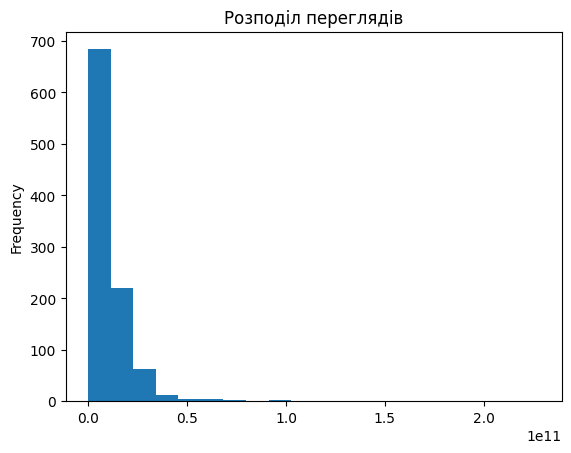

Максимум переглядів: 228000000000.0
Мінімум переглядів: 0.0
Середнє значення переглядів: 11039537052.03819
Країна з найбільшою кількістю завантажень: India
Канал з макс. завантаженнями: ABP NEWS
Канал з мін. завантаженнями: Music


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Читаємо файл
df = pd.read_csv('/content/Global YouTube Statistics.csv', encoding='unicode_escape')

# 2. Виведення перших п'яти рядків
print(df.head())

# 3. Розміри датасету
print(f"Розмір датасету: {df.shape}")

# 4. Перевірка пропусків
print("Кількість пропусків у кожному стовпці:")
print(df.isna().sum())

# Замінюємо пусті значення на NaN та приводимо до числового типу
cols_to_fix = ['video views', 'uploads', 'subscribers']
for col in cols_to_fix:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    # 5. Заміна пропусків на середнє значення та тип float
    df[col] = df[col].fillna(df[col].mean()).astype(float)

# 6. Ще раз перевіряємо кількість пропусків
print("\nПропуски після обробки:")
print(df.isna().sum())

# 7. Кількість унікальних країн
print(f"\nКількість унікальних країн: {df['Country'].nunique()}")

# 8. Діаграма розподілу переглядів
df['video views'].plot(kind='hist', bins=20)
plt.title('Розподіл переглядів')
plt.show()

# 9. Максимальна, мінімальна та середня кількість переглядів
print(f"Максимум переглядів: {df['video views'].max()}")
print(f"Мінімум переглядів: {df['video views'].min()}")
print(f"Середнє значення переглядів: {df['video views'].mean()}")

# 10. Країна з найбільшою кількістю завантажень
country_uploads = df.groupby('Country')['uploads'].sum().idxmax()
print(f"Країна з найбільшою кількістю завантажень: {country_uploads}")

# 11. Відео з найбільшою та найменшою кількістю завантажень
video_max = df.loc[df['uploads'].idxmax(), 'Youtuber']
video_min = df.loc[df['uploads'].idxmin(), 'Youtuber']
print(f"Канал з макс. завантаженнями: {video_max}")
print(f"Канал з мін. завантаженнями: {video_min}")

In [5]:
import pandas as pd

# 1. Прочитайте csv файл
df_books = pd.read_csv('/content/bestsellers with categories.csv')

# Виведіть перші 10 рядків
print(df_books.head(10))

# Виведіть розміри датасету
print(f"Розмір датасету: {df_books.shape}")

# Про скільки книг зберігає дані датасет?
print(f"Кількість книг у датасеті: {df_books.shape[0]}")

# Змініть назви всіх колонок
df_books.columns = ['name', 'author', 'user_rating', 'reviews', 'price', 'year', 'genre']
print("\nНові назви колонок:")
print(df_books.columns)

# Вивести кількість пропусків у кожному стовпчику
print("\nКількість пропусків:")
print(df_books.isna().sum())
# Чи є в якихось змінних пропуски? (Відповідь: Ні)

# Унікальні жанри
unique_genres = df_books['genre'].unique()
print(f"\nУнікальні жанри: {unique_genres}")

# Визначте максимальну, мінімальну, середню та медіанну ціну
print(f"Максимальна ціна: {df_books['price'].max()}")
print(f"Мінімальна ціна: {df_books['price'].min()}")
print(f"Середня ціна: {df_books['price'].mean()}")
print(f"Медіанна ціна: {df_books['price'].median()}")

# 8. Пошук і сортування
max_rating = df_books['user_rating'].max()
print(f"\nНайвищий рейтинг: {max_rating}")

count_max_rating = len(df_books[df_books['user_rating'] == max_rating])
print(f"Кількість книг з таким рейтингом: {count_max_rating}")

most_reviews_book = df_books.loc[df_books['reviews'].idxmax(), 'name']
print(f"Книга з найбільшою кількістю відгуків: {most_reviews_book}")

expensive_2010 = df_books[df_books['year'] == 2010].sort_values('price', ascending=False).iloc[0]['name']
print(f"Найдорожча книга 2010 року: {expensive_2010}")

fiction_2012 = len(df_books[(df_books['genre'] == 'Fiction') & (df_books['year'] == 2012)])
print(f"Кількість книг Fiction у 2012 році: {fiction_2012}")

rating_49_count = len(df_books[(df_books['user_rating'] == 4.9) & (df_books['year'].isin([2010, 2011]))])
print(f"Книг з рейтингом 4.9 у 2010 та 2011 роках: {rating_49_count}")

# Вивести макс і мін ціну для жанрів Fiction і Non Fiction
print("\nМаксимальна та мінімальна ціна за жанрами:")
genre_agg = df_books.groupby('genre')['price'].agg(['max', 'min'])
print(genre_agg)

                                                Name  \
0                      10-Day Green Smoothie Cleanse   
1                                  11/22/63: A Novel   
2            12 Rules for Life: An Antidote to Chaos   
3                             1984 (Signet Classics)   
4  5,000 Awesome Facts (About Everything!) (Natio...   
5      A Dance with Dragons (A Song of Ice and Fire)   
6  A Game of Thrones / A Clash of Kings / A Storm...   
7                     A Gentleman in Moscow: A Novel   
8      A Higher Loyalty: Truth, Lies, and Leadership   
9                          A Man Called Ove: A Novel   

                     Author  User Rating  Reviews  Price  Year        Genre  
0                  JJ Smith          4.7    17350      8  2016  Non Fiction  
1              Stephen King          4.6     2052     22  2011      Fiction  
2        Jordan B. Peterson          4.7    18979     15  2018  Non Fiction  
3             George Orwell          4.7    21424      6  2017      Fic